# Thống kê dữ liệu bình luận Mưa Đỏ


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Nếu mở notebook trong VS Code, thư mục làm việc có thể là notebooks hoặc BTL1-NLP.
duong_dan = Path.cwd().resolve()
while not (duong_dan / 'xu_ly_data').is_dir():
    if duong_dan == duong_dan.parent:
        raise FileNotFoundError('Hãy mở notebook trong thư mục dự án BTL1-NLP')
    duong_dan = duong_dan.parent
thu_muc = duong_dan / 'xu_ly_data'
anh = thu_muc / 'bieu_do_thong_ke'
anh.mkdir(parents=True, exist_ok=True)

## 1. Dữ liệu đầu vào sau khi crawl
Thống kê số link trong `post_urls.txt`.

In [2]:
with open(thu_muc / 'data/crawl_data/post_urls.txt', encoding='utf-8-sig') as f:
    links = [dong.strip() for dong in f if dong.strip() and not dong.lstrip().startswith('#')]
print('Tổng số dòng link:', len(links))
print('Số link khác nhau:', len(set(links)))
print('Số dòng link trùng:', len(links) - len(set(links)))

Tổng số dòng link: 98
Số link khác nhau: 98
Số dòng link trùng: 0


Trùng nội dung được tính sau khi chuẩn hóa Unicode, chữ thường và khoảng trắng, không tính dòng xuất hiện đầu tiên.

Tổng số mẫu crawl: 6539
Số dòng trùng nội dung: 449
Số dòng nội dung rỗng: 0


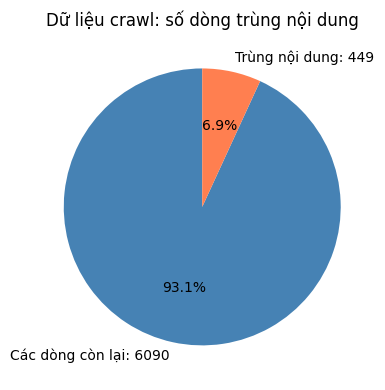

In [3]:
df_crawl = pd.read_csv(thu_muc / 'data/crawl_data/facebook_comments_all.csv', dtype=str).fillna('')
noi_dung = df_crawl['comment'].str.normalize('NFC').str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
trung = noi_dung[noi_dung != ''].duplicated().sum()
print('Tổng số mẫu crawl:', len(df_crawl))
print('Số dòng trùng nội dung:', trung)
print('Số dòng nội dung rỗng:', (noi_dung == '').sum())
plt.figure(figsize=(7, 4))
plt.pie([len(df_crawl) - trung, trung], labels=[f'Các dòng còn lại: {len(df_crawl) - trung}', f'Trùng nội dung: {trung}'], autopct='%1.1f%%', colors=['steelblue', 'coral'], startangle=90)
plt.title('Dữ liệu crawl: số dòng trùng nội dung')
plt.tight_layout()
plt.savefig(anh / '01_du_lieu_crawl_tron.png', dpi=180)
plt.show()

## 2. Dữ liệu đã gán nhãn
Nguồn `data_labeled.csv`, trước tiền xử lý.

Tổng số mẫu: 7067
Số mẫu theo nhãn:
label
non-toxic    6489
toxic         578
Name: count, dtype: int64
Số biến thể AI: 528


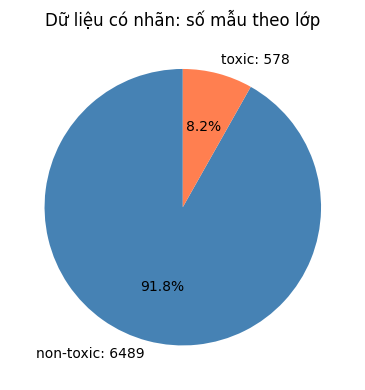

In [4]:
df = pd.read_csv(thu_muc / 'data/data/input/data_labeled.csv', dtype=str).fillna('')
df['label'] = df['label'].str.strip().str.lower().replace({'0': 'non-toxic', '1': 'toxic'})
print('Tổng số mẫu:', len(df))
print('Số mẫu theo nhãn:')
print(df['label'].value_counts())
print('Số biến thể AI:', df['is_synthetic'].str.lower().isin(['true', '1']).sum())
so_luong = df['label'].value_counts().reindex(['non-toxic', 'toxic'], fill_value=0)
plt.figure(figsize=(7, 4))
plt.pie(so_luong.values, labels=[f'{ten}: {so}' for ten, so in so_luong.items()], autopct='%1.1f%%', colors=['steelblue', 'coral'], startangle=90)
plt.title('Dữ liệu có nhãn: số mẫu theo lớp')
plt.tight_layout()
plt.savefig(anh / '02_nhan_dau_vao_tron.png', dpi=180)
plt.show()

### Số mẫu theo lớp của dữ liệu nguyên bản
Chỉ tính các dòng `is_synthetic = False`, không gồm biến thể AI.

Tổng mẫu nguyên bản: 6539
label
non-toxic    6489
toxic          50
Name: count, dtype: int64


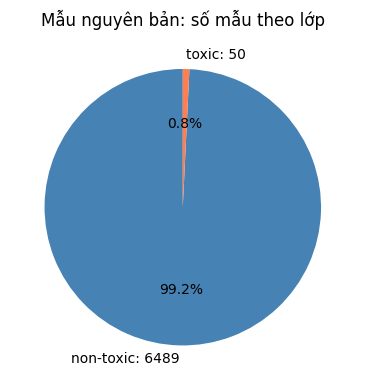

In [5]:
df_nguyen_ban = df[df['is_synthetic'].str.lower().isin(['false', '0'])]
so_luong_goc = df_nguyen_ban['label'].value_counts().reindex(['non-toxic', 'toxic'], fill_value=0)
print('Tổng mẫu nguyên bản:', len(df_nguyen_ban))
print(so_luong_goc)
plt.figure(figsize=(7, 4))
plt.pie(so_luong_goc.values, labels=[f'{ten}: {so}' for ten, so in so_luong_goc.items()], autopct='%1.1f%%', colors=['steelblue', 'coral'], startangle=90)
plt.title('Mẫu nguyên bản: số mẫu theo lớp')
plt.tight_layout()
plt.savefig(anh / '06_nhan_mau_nguyen_ban_tron.png', dpi=180)
plt.show()

In [6]:
print('Tổng số mẫu đã gán nhãn:', len(df))
print('Trong đó biến thể AI:', df['is_synthetic'].str.lower().isin(['true', '1']).sum())

Tổng số mẫu đã gán nhãn: 7067
Trong đó biến thể AI: 528


## 3. Dữ liệu sau tiền xử lý, trước chia tập
Nguồn `comments_preprocessed.csv`.

Tổng số mẫu: 6553
Số mẫu theo nhãn:
label
non-toxic    5982
toxic         571
Name: count, dtype: int64
Số biến thể AI: 522
Số dòng giảm so với đầu vào có nhãn: 514


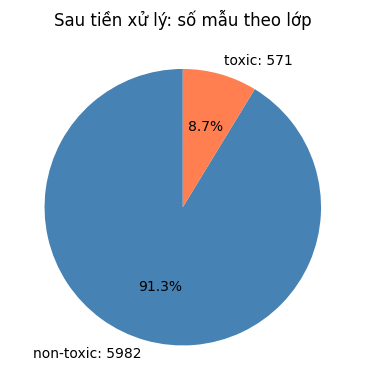

In [7]:
df_processed = pd.read_csv(thu_muc / 'data/data/pre_split/comments_preprocessed.csv', dtype=str).fillna('')
df_processed['label'] = df_processed['label'].str.strip().str.lower().replace({'0': 'non-toxic', '1': 'toxic'})
print('Tổng số mẫu:', len(df_processed))
print('Số mẫu theo nhãn:')
print(df_processed['label'].value_counts())
print('Số biến thể AI:', df_processed['is_synthetic'].str.lower().isin(['true', '1']).sum())
print('Số dòng giảm so với đầu vào có nhãn:', len(df) - len(df_processed))
so_luong_sau = df_processed['label'].value_counts().reindex(['non-toxic', 'toxic'], fill_value=0)
plt.figure(figsize=(7, 4))
plt.pie(so_luong_sau.values, labels=[f'{ten}: {so}' for ten, so in so_luong_sau.items()], autopct='%1.1f%%', colors=['steelblue', 'coral'], startangle=90)
plt.title('Sau tiền xử lý: số mẫu theo lớp')
plt.tight_layout()
plt.savefig(anh / '04_nhan_sau_xu_ly_tron.png', dpi=180)
plt.show()

Số dòng trùng ở mục 1 có thể khác số dòng bị loại trong tiền xử lý vì hai bước dùng cách so sánh văn bản khác nhau.